In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [ ]:
companies = [
    "SamsungBiologics",
    "Naver",
    "Skhynix",
    "PoscoHoldings",
    "Kia",
    "Lgchem",
    "Kbfg",
    "Samsung",
    "Hyundai",
    "Lgensol"
]

input_folder = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/train_result_Date"

In [ ]:
def run_backtest(df, initial_capital=10000000):
    df = df.copy()
    df['capital'] = np.nan
    df['return_rate'] = np.nan
    df['position'] = ''

    capital = float(initial_capital)
    position = 0

    if not df.empty:
        df.loc[df.index[0], 'capital'] = capital
        df.loc[df.index[0], 'return_rate'] = 0.0
        df.loc[df.index[0], 'position'] = 'observation'

    for i in range(1, len(df)):
        current_sentiment = df.loc[df.index[i], 'emotion']
        previous_price = df.loc[df.index[i-1], 'y_pred']
        current_price = df.loc[df.index[i], 'y_pred']

        if current_sentiment == 1 and position == 0:
            position = 1
            df.loc[df.index[i], 'position'] = 'buy'
        elif current_sentiment == -1 and position == 1:
            position = 0
            df.loc[df.index[i], 'position'] = 'sell'
        else:
            df.loc[df.index[i], 'position'] = df.loc[df.index[i-1], 'position']

        if position == 1:
            capital *= (current_price / previous_price)

        df.loc[df.index[i], 'capital'] = capital
        df.loc[df.index[i], 'return_rate'] = ((capital - initial_capital) / initial_capital) * 100

    return df

In [ ]:
def visualize_backtest(df, company_name, initial_capital=10000000):
    buy_and_hold_capital = df['y_pred'] / df['y_pred'].iloc[0] * initial_capital
    buy_and_hold_return = (buy_and_hold_capital - initial_capital) / initial_capital * 100

    plt.figure(figsize=(16, 8))
    plt.plot(df['date'], df['return_rate'], label='Sentiment Strategy', color='blue', linewidth=2)
    plt.plot(df['date'], buy_and_hold_return, label='Buy & Hold', color='red', linestyle='--', linewidth=2)
    plt.title(f"{company_name} Backtest")
    plt.xlabel("Date")
    plt.ylabel("Cumulative Return (%)")
    plt.legend()
    plt.gca().yaxis.set_major_formatter(ticker.PercentFormatter())
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

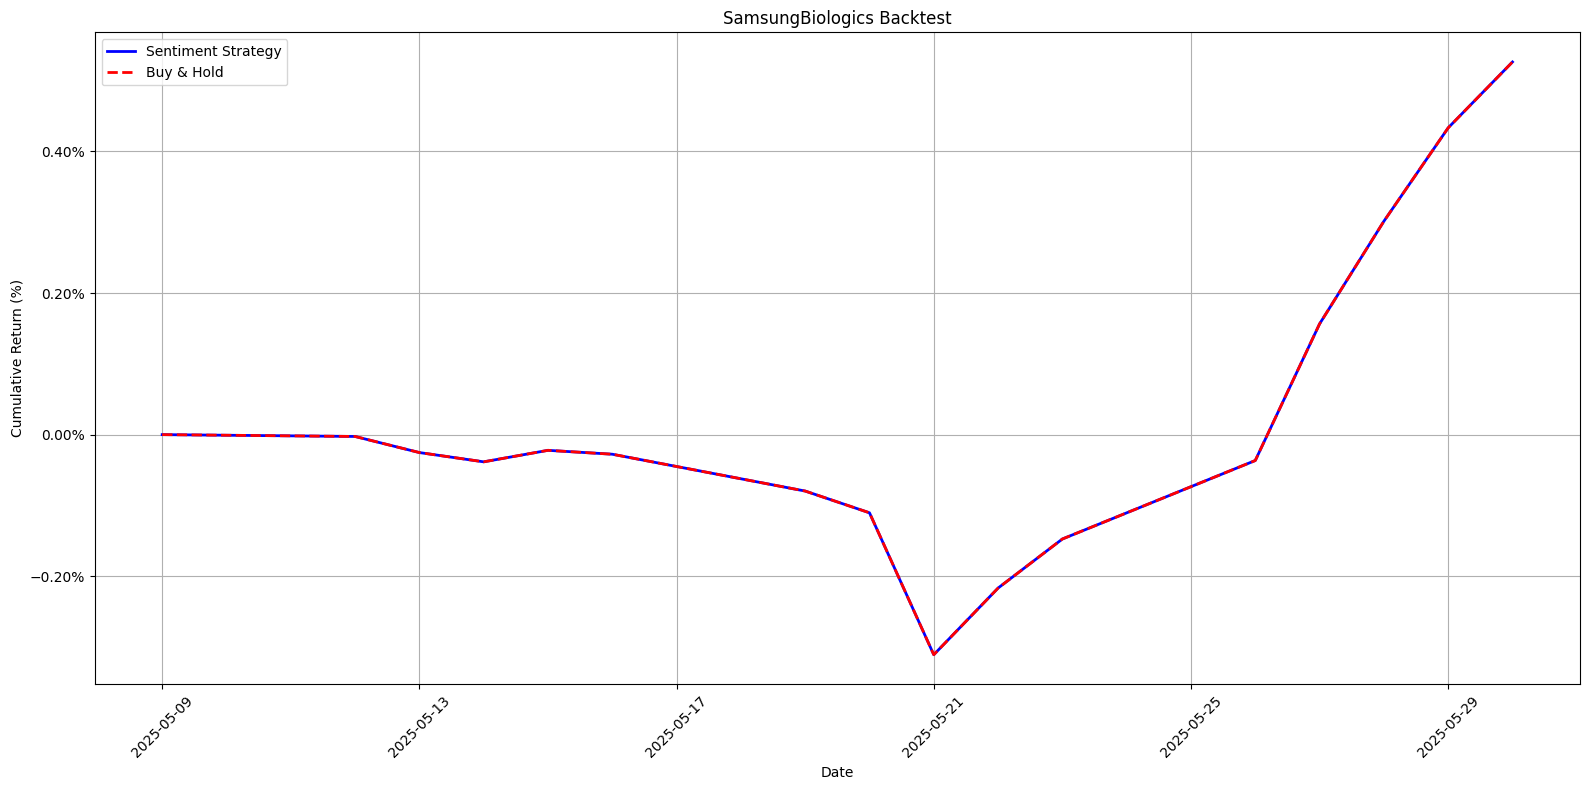

SamsungBiologics 최종 자본: 10,052,643 KRW, 최종 수익률: 0.53%


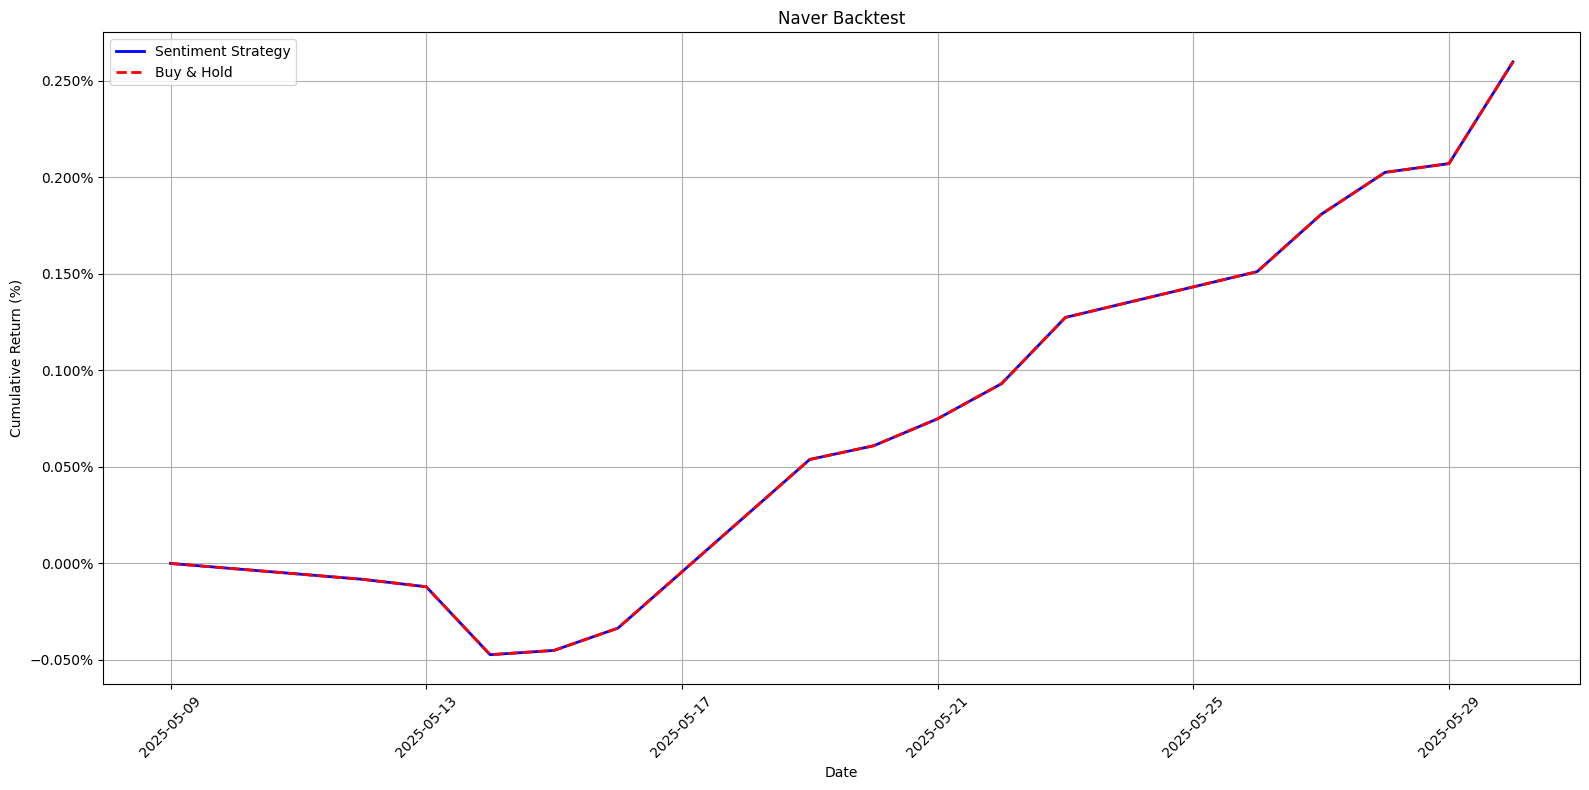

Naver 최종 자본: 10,025,980 KRW, 최종 수익률: 0.26%


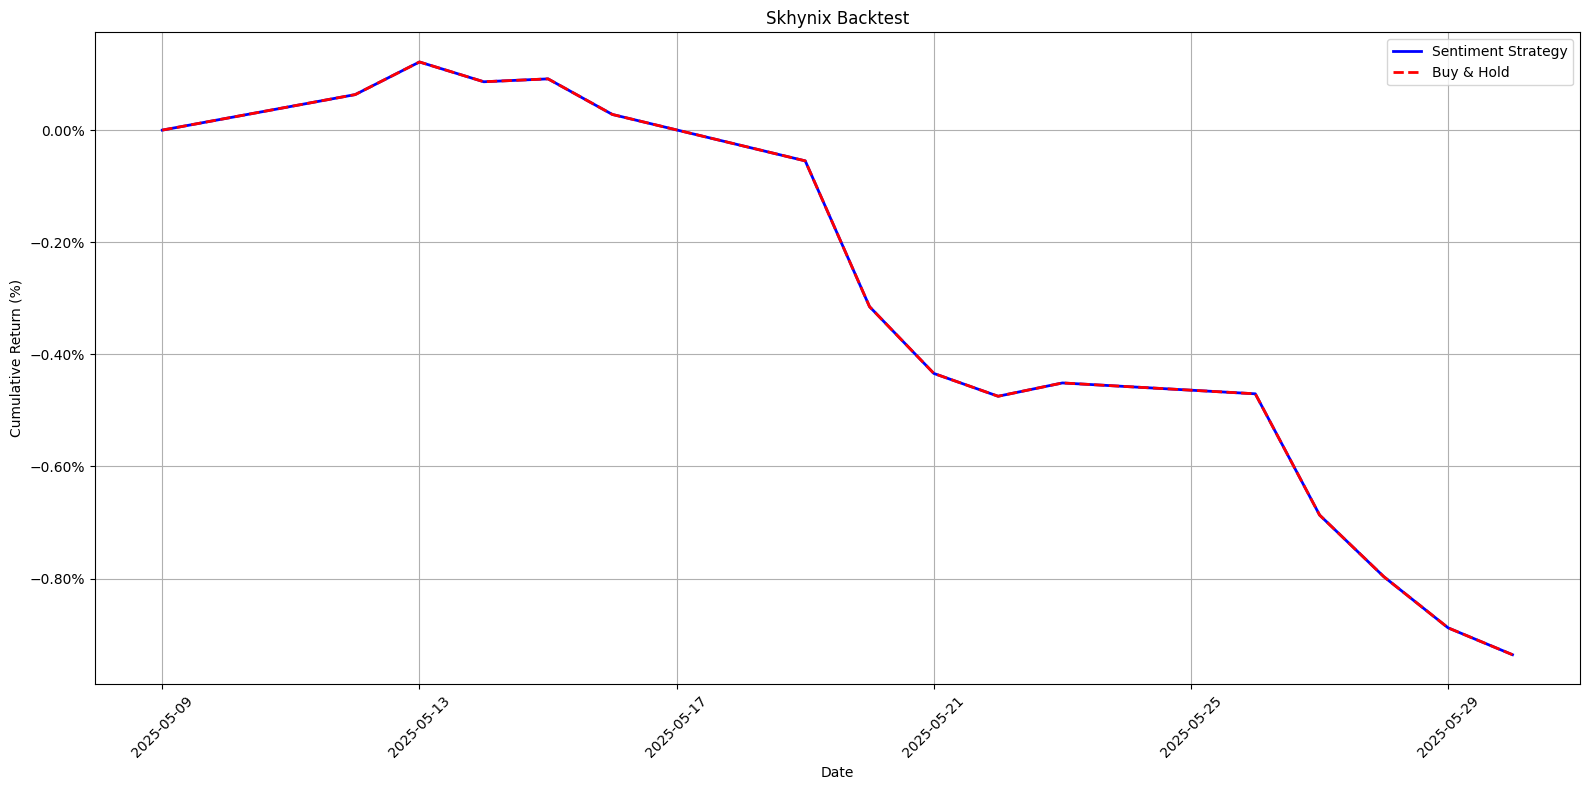

Skhynix 최종 자본: 9,906,409 KRW, 최종 수익률: -0.94%


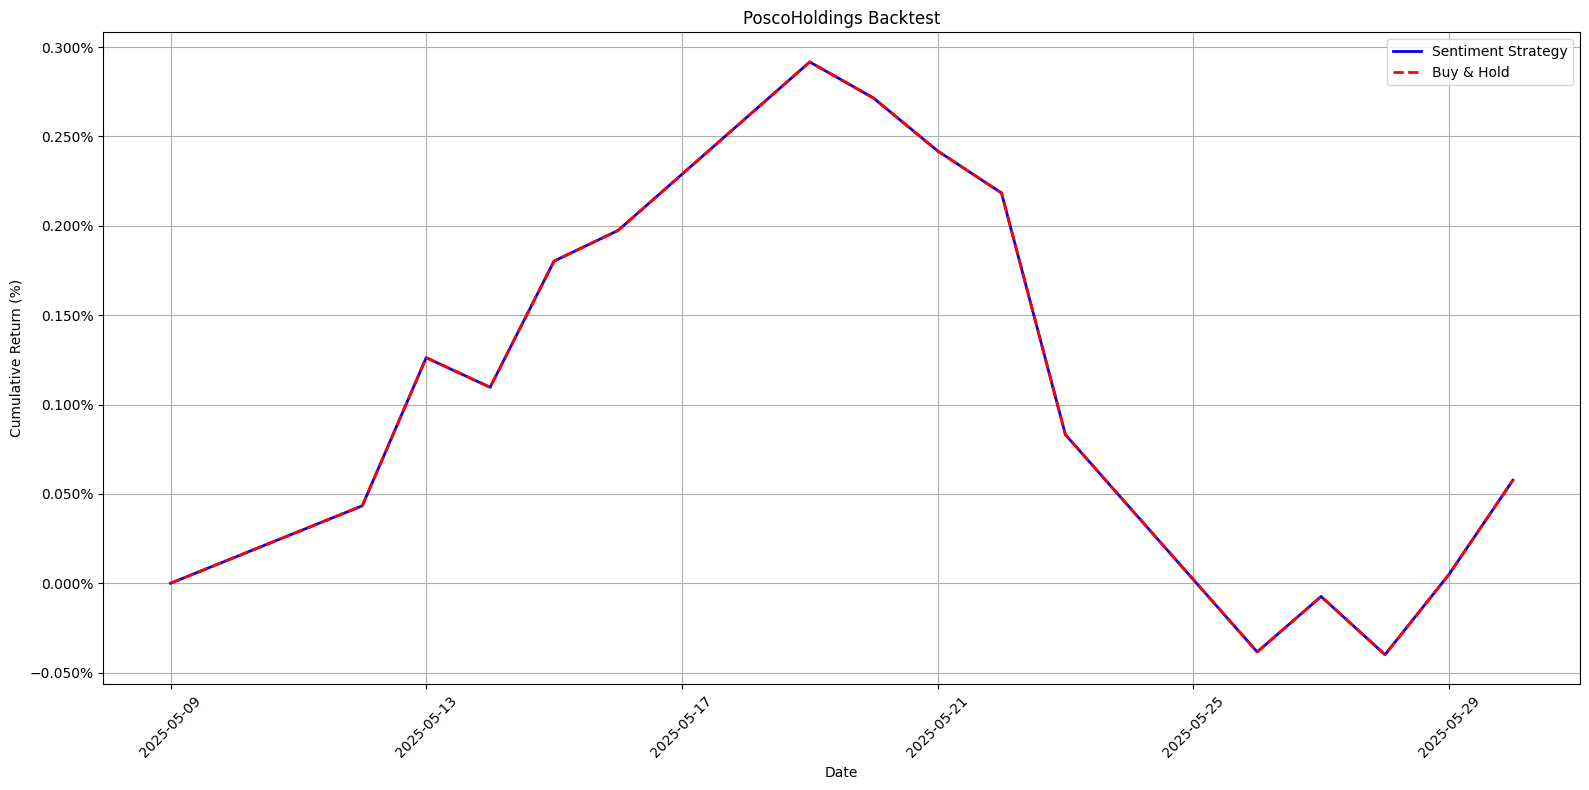

PoscoHoldings 최종 자본: 10,005,767 KRW, 최종 수익률: 0.06%


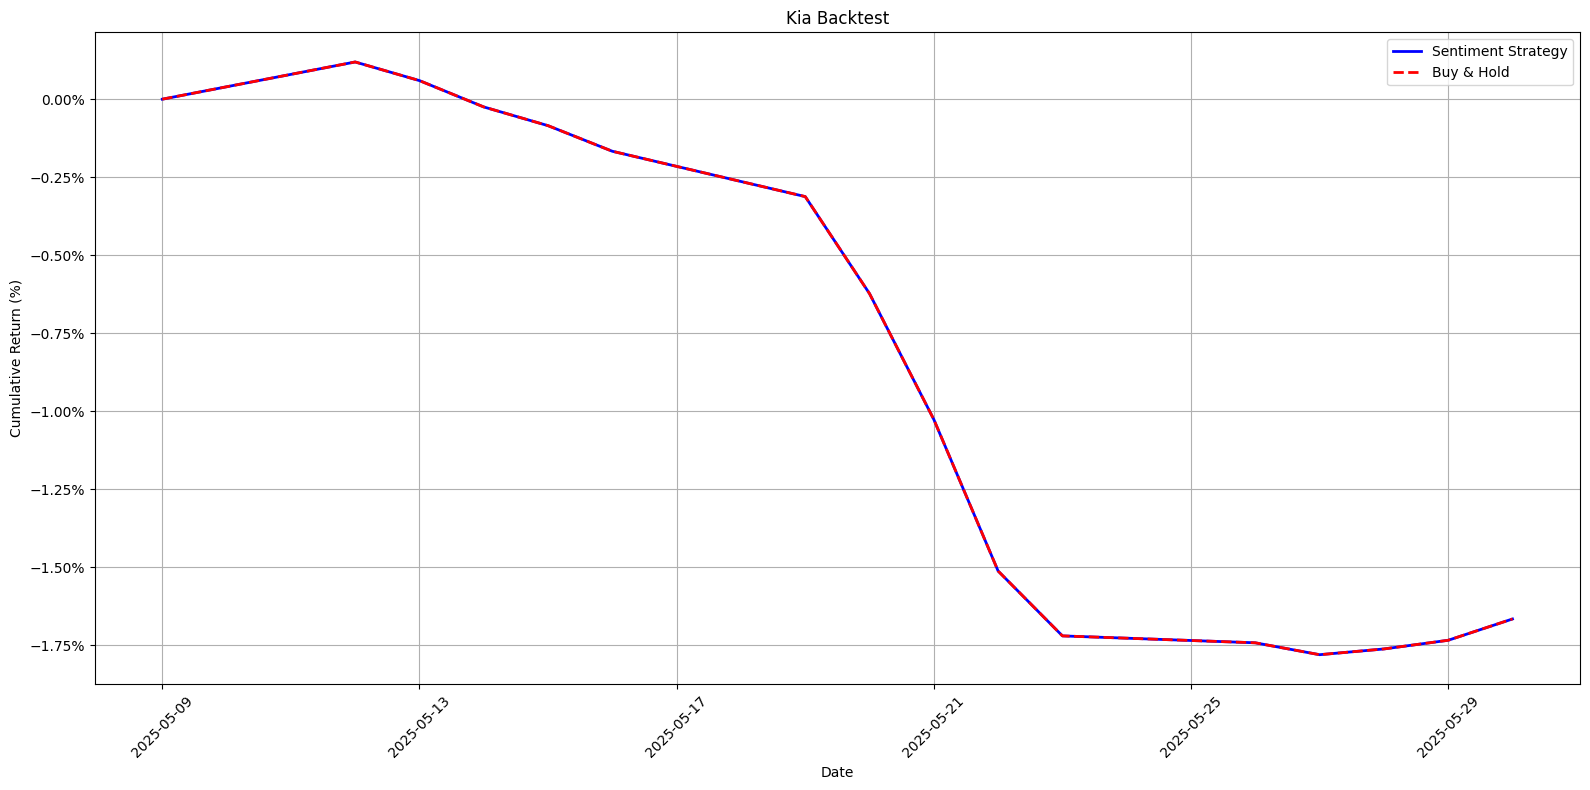

Kia 최종 자본: 9,833,449 KRW, 최종 수익률: -1.67%


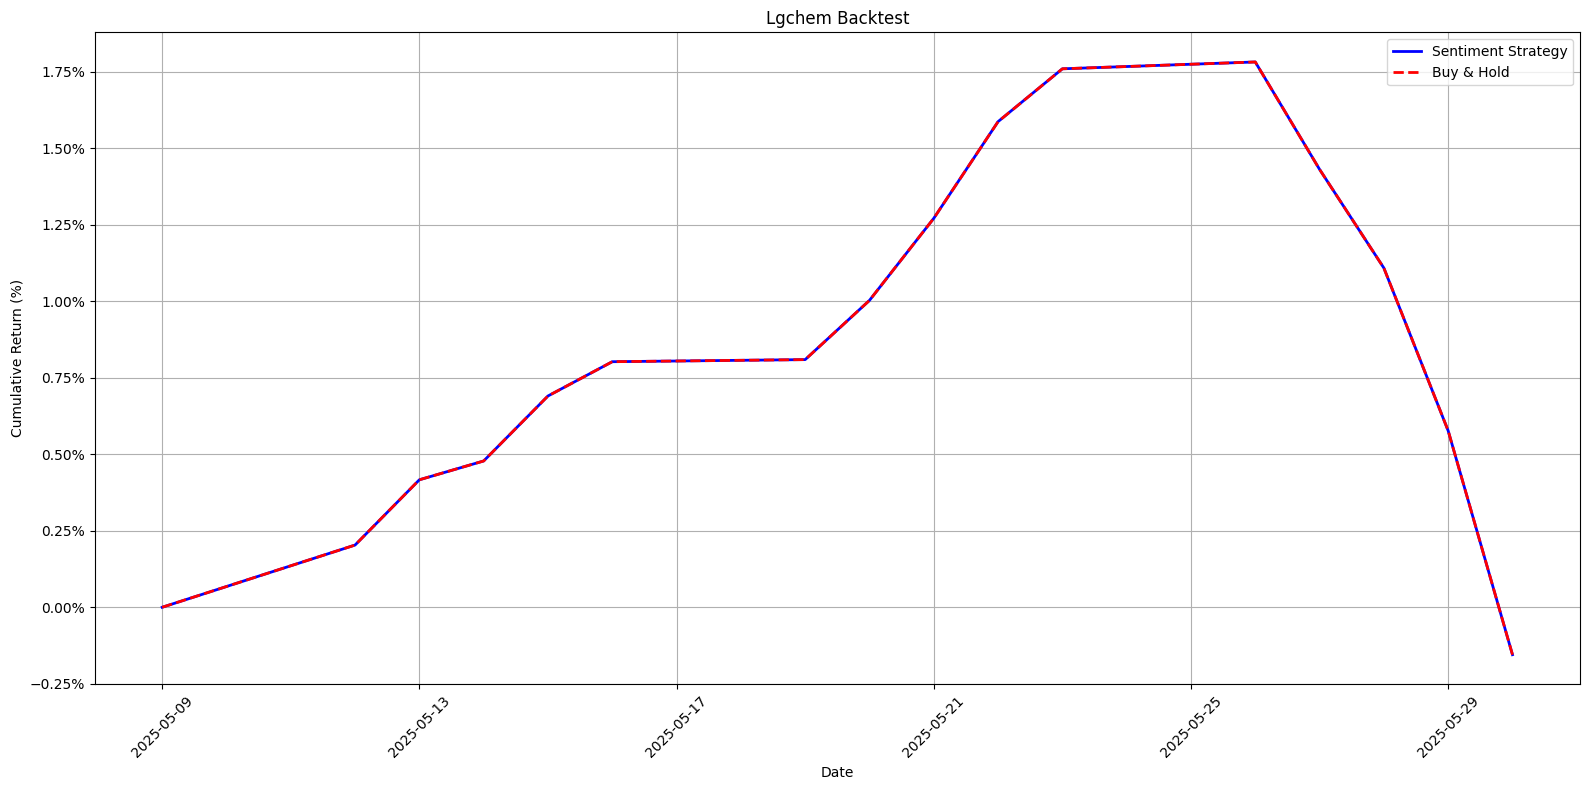

Lgchem 최종 자본: 9,984,499 KRW, 최종 수익률: -0.16%


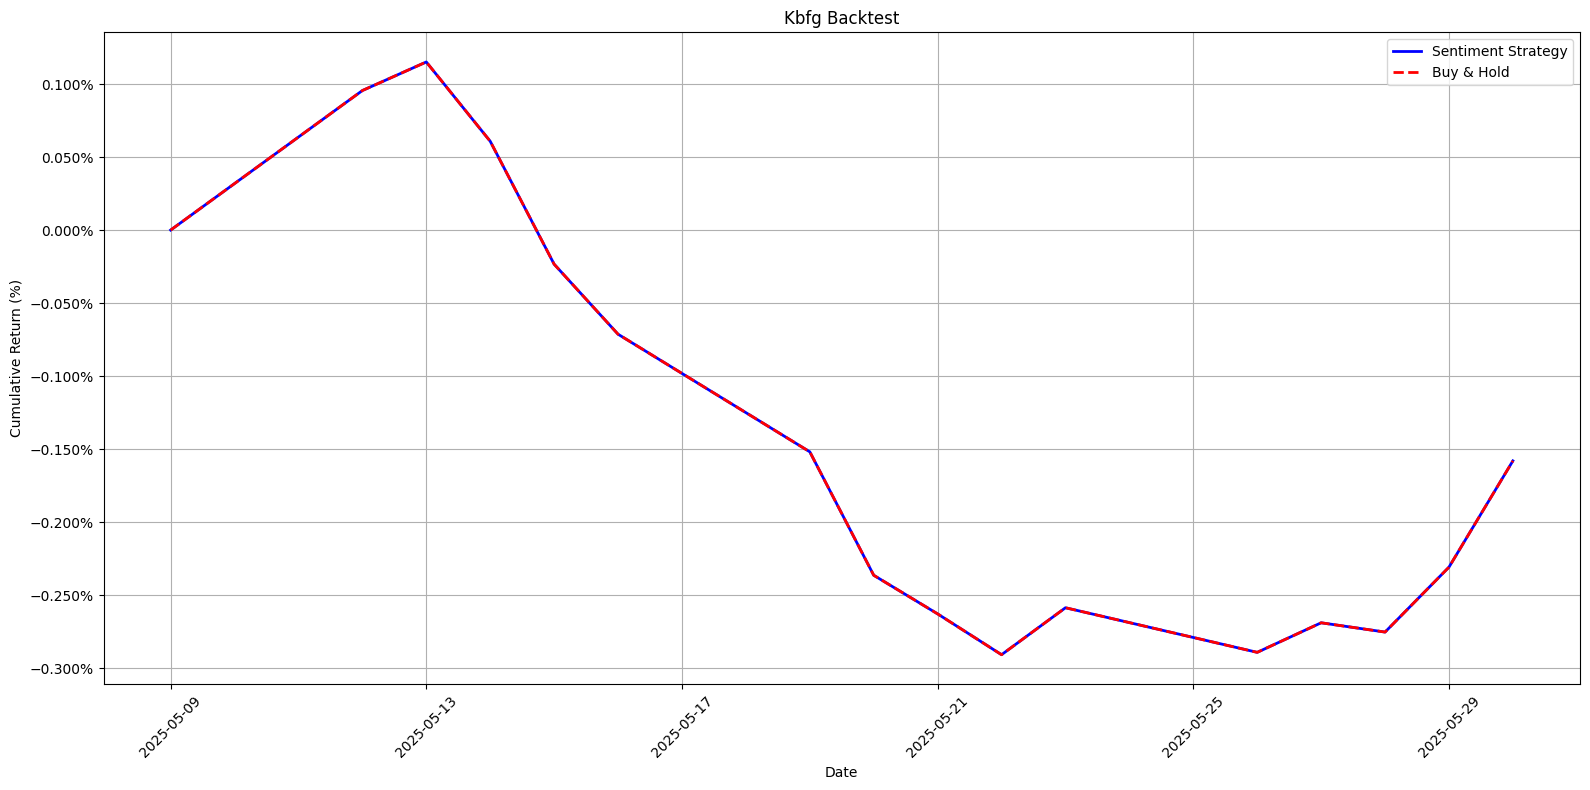

Kbfg 최종 자본: 9,984,197 KRW, 최종 수익률: -0.16%


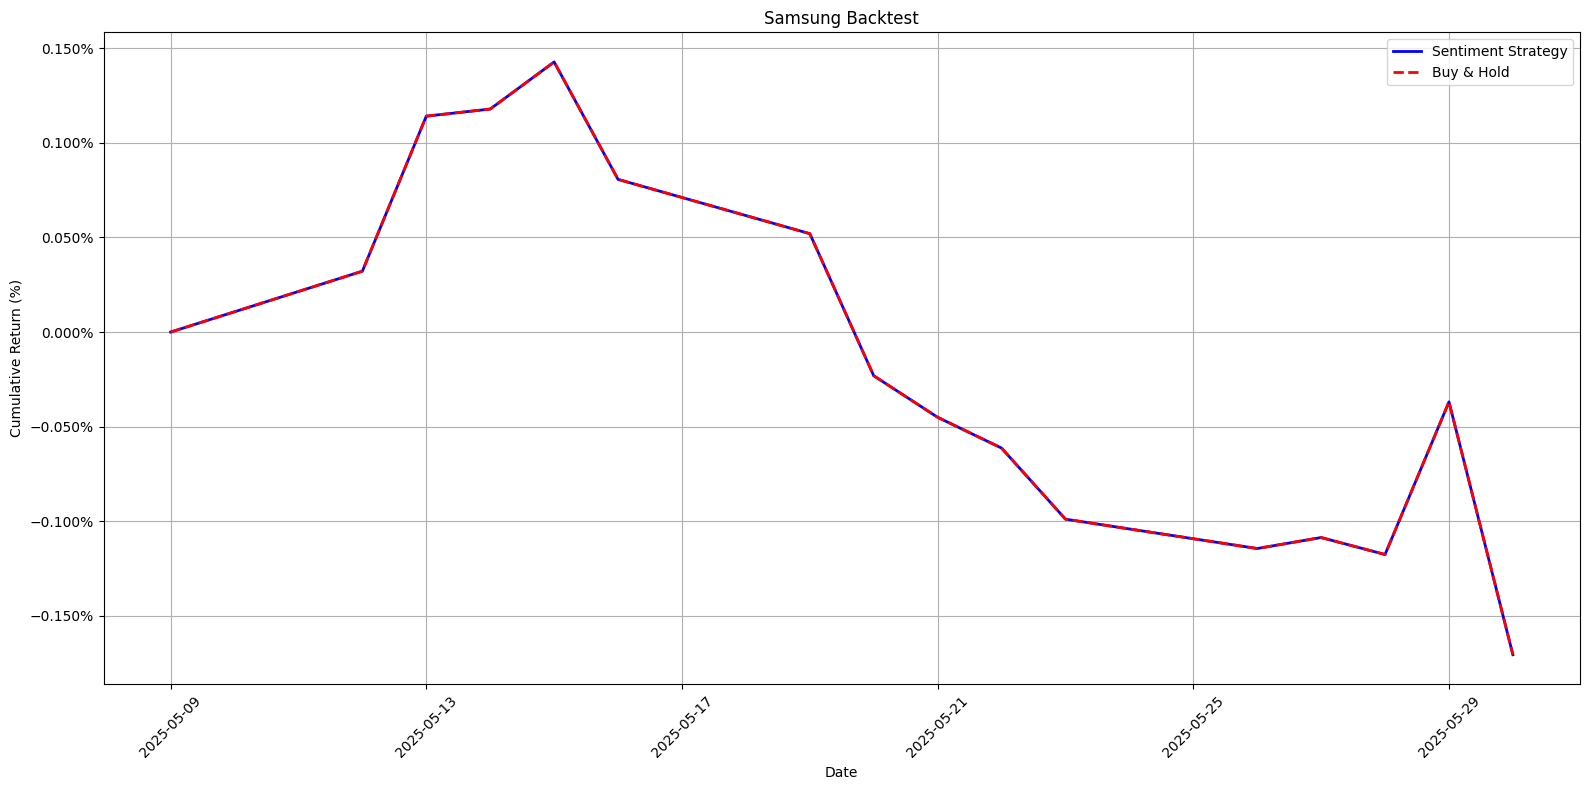

Samsung 최종 자본: 9,982,942 KRW, 최종 수익률: -0.17%


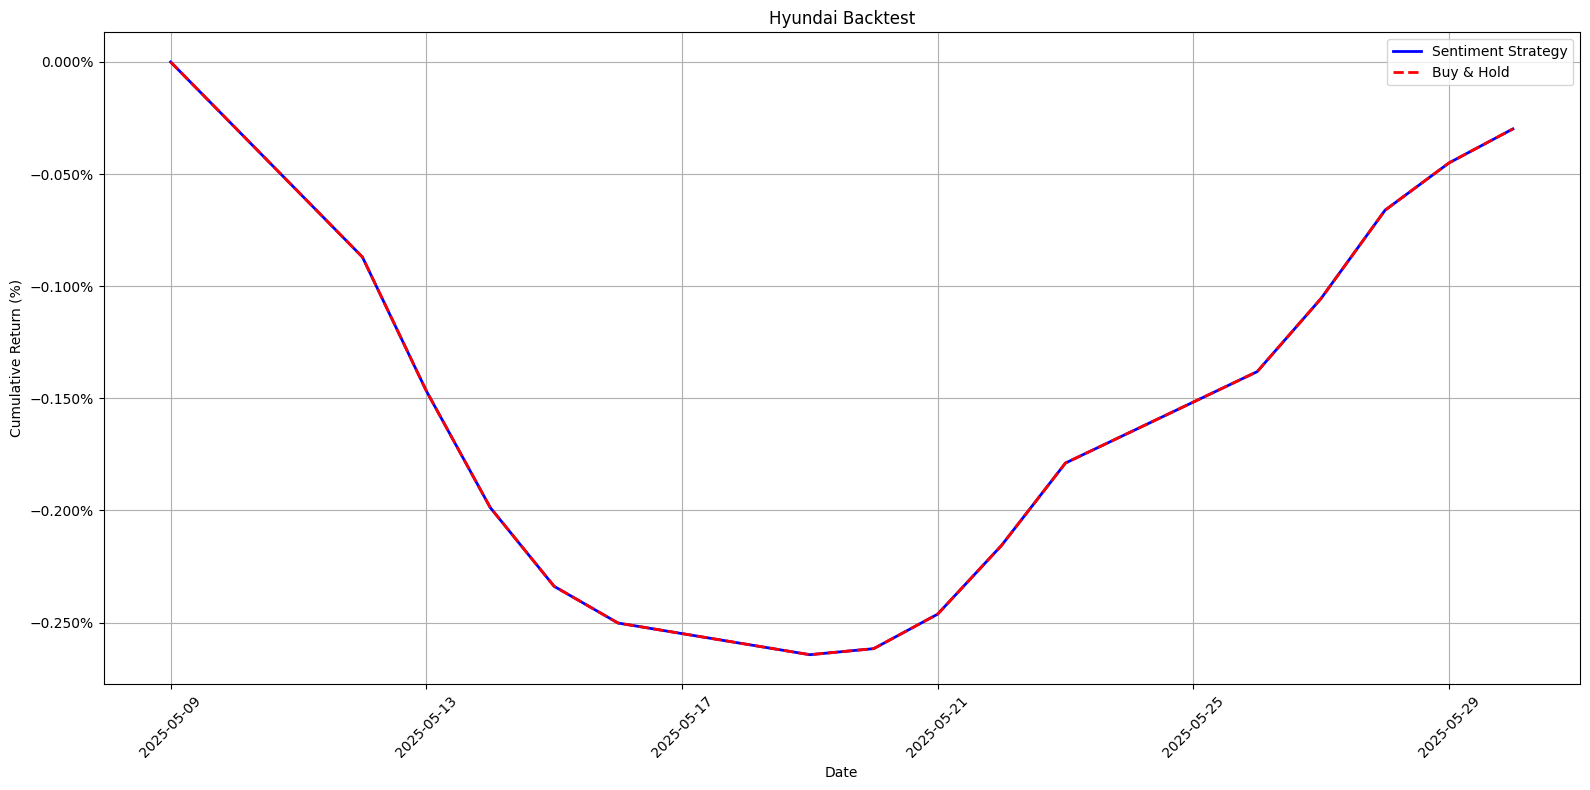

Hyundai 최종 자본: 9,997,015 KRW, 최종 수익률: -0.03%


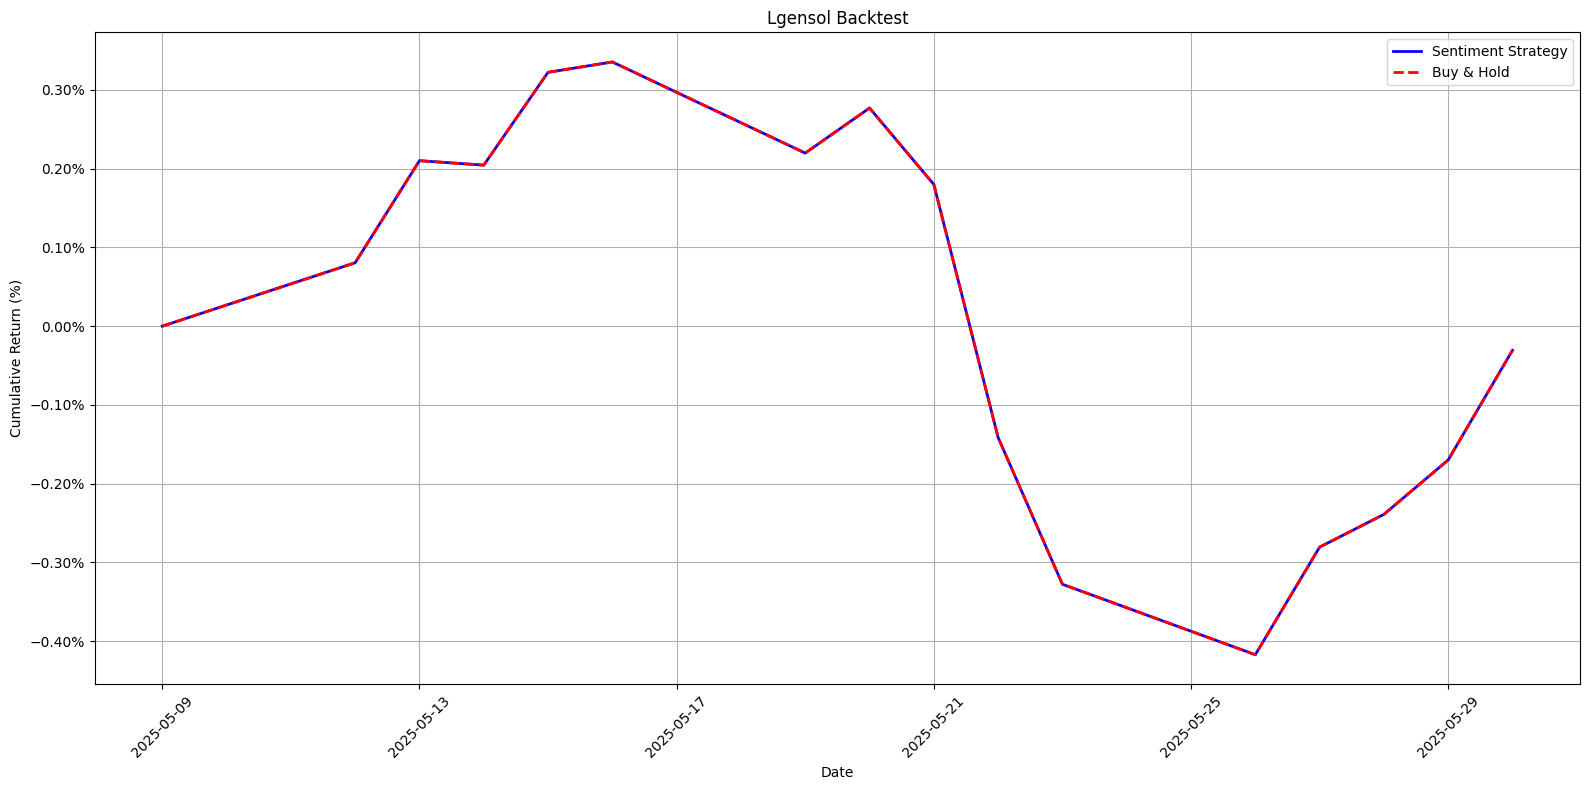

Lgensol 최종 자본: 9,996,937 KRW, 최종 수익률: -0.03%


In [ ]:
initial_capital = 10000000
for company in companies:
    file_path = os.path.join(input_folder, f"result_{company}.csv")
    df = pd.read_csv(file_path)

    if 'emotion' not in df.columns:
        print(f"⚠️ {company} emotion 컬럼 없음, 스킵")
        continue

    df['date'] = pd.to_datetime(df['date'])
    backtest_df = run_backtest(df, initial_capital)
    visualize_backtest(backtest_df, company)
    final_capital = backtest_df['capital'].iloc[-1]
    final_return = backtest_df['return_rate'].iloc[-1]
    print(f"{company} 최종 자본: {final_capital:,.0f} KRW, 최종 수익률: {final_return:.2f}%")